
# CIFAR-100 — Set Transformer Experiments

## Objective

This experiment compares five neural network architectures on the CIFAR-100 image classification dataset.

The models evaluated are:

- Standard Transformer
- Set Transformer (ISAB + PMA + SAB)
- ISAB + PMA
- SAB + PMA
- MLP Baseline

Each image is resized to 96 × 96 pixels and divided into 144 non-overlapping 8 × 8 patches. Each patch is represented by 192 RGB pixel values and 2 spatial coordinates, producing 194 features per patch.

The resulting collection of patches is processed as a set to predict one of 100 image classes.

The objective is to investigate how different attention mechanisms perform on image classification and whether permutation-invariant architectures can effectively learn spatial relationships from image patches.


In [1]:
import os

os.chdir("/work/classes/ai4200-001-2026f/jfinnegan42/Set-Transformer")

print("Current directory:", os.getcwd())
print("Results folder exists:", os.path.exists("results"))

Current directory: /work/classes/ai4200-001-2026f/jfinnegan42/Set-Transformer
Results folder exists: True


In [2]:
import os
import sys
import subprocess
from pathlib import Path

result = subprocess.run(
    ["spack", "location", "-i", "py-torchvision@0.24.1"],
    capture_output=True,
    text=True
)

root = Path(result.stdout.strip())
site_packages = root / "lib" / "python3.13" / "site-packages"

sys.path.insert(0, str(site_packages))

env = os.environ.copy()
env["PYTHONPATH"] = os.pathsep.join(sys.path)

import torch
import torchvision

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")

PyTorch: 2.9.1
Torchvision: 0.24.1
GPU: NVIDIA A100-PCIE-40GB



## Model Training

All five models were trained using the same experimental configuration to compare their performance on CIFAR-100.

### Training Configuration

- **Dataset:** CIFAR-100
- **Training samples:** 45,000
- **Validation samples:** 5,000
- **Test samples:** 10,000
- **Image resolution:** 96 × 96 pixels
- **Patches per image:** 144
- **Features per patch:** 194
- **Number of classes:** 100
- **Epochs:** 20
- **Batch size:** 32
- **Optimizer:** AdamW
- **Learning rate:** 0.0003
- **Weight decay:** 0.0001
- **Learning rate scheduler:** Cosine annealing
- **Loss function:** Cross-entropy
- **Random seed:** 42

The same training procedure was applied to each architecture. The checkpoint with the lowest validation loss was selected for final evaluation on the held-out test set.

Model performance was evaluated using classification accuracy and cross-entropy loss.


In [10]:
import subprocess
import sys
import os

env = os.environ.copy()
env["PYTHONPATH"] = os.pathsep.join(sys.path)

models = ["standard", "set", "isab", "sab", "baseline"]

for model in models:
    print(f"\n{'=' * 60}", flush=True)
    print(f"Training {model.upper()} on CIFAR-100", flush=True)
    print(f"{'=' * 60}", flush=True)

    command = [
        sys.executable, "-u", "train.py",
        "--dataset", "cifar",
        "--model", model,
        "--epochs", "20",
        "--batch-size", "32"
    ]

    result = subprocess.run(command, env=env)

    if result.returncode != 0:
        print(f"FAILED: {model}", flush=True)
        break

print("\nCIFAR-100 training finished.", flush=True)


Training STANDARD on CIFAR-100
Device: cuda


/opt/ohpc/pub/spack/v1.1.1/opt/spack/linux-x86_64_v3/py-torchvision-0.24.1-nrd7fnlihzwuiygwxebprfqnixobjtvw/lib/python3.13/site-packages/torchvision/datasets/cifar.py:83: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  entry = pickle.load(f, encoding="latin1")


Training fraction: 100%
Training examples: 45000
Validation examples: 5000
Test examples: 10000

STANDARD / CIFAR / 434,404 parameters
Epoch 01/20 | train loss 3.9405 | val loss 3.5791 | val accuracy 0.1482
Epoch 02/20 | train loss 3.4343 | val loss 3.2599 | val accuracy 0.2132
Epoch 03/20 | train loss 3.1389 | val loss 3.0132 | val accuracy 0.2544
Epoch 04/20 | train loss 2.9249 | val loss 2.8513 | val accuracy 0.2834
Epoch 05/20 | train loss 2.7606 | val loss 2.7795 | val accuracy 0.3072
Epoch 06/20 | train loss 2.6299 | val loss 2.7143 | val accuracy 0.3080
Epoch 07/20 | train loss 2.5186 | val loss 2.5993 | val accuracy 0.3438
Epoch 08/20 | train loss 2.4207 | val loss 2.5491 | val accuracy 0.3498
Epoch 09/20 | train loss 2.3321 | val loss 2.4905 | val accuracy 0.3612
Epoch 10/20 | train loss 2.2498 | val loss 2.4680 | val accuracy 0.3662
Epoch 11/20 | train loss 2.1708 | val loss 2.4034 | val accuracy 0.3860
Epoch 12/20 | train loss 2.1061 | val loss 2.3794 | val accuracy 0.3872
E

/opt/ohpc/pub/spack/v1.1.1/opt/spack/linux-x86_64_v3/py-torchvision-0.24.1-nrd7fnlihzwuiygwxebprfqnixobjtvw/lib/python3.13/site-packages/torchvision/datasets/cifar.py:83: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  entry = pickle.load(f, encoding="latin1")


Training fraction: 100%
Training examples: 45000
Validation examples: 5000
Test examples: 10000

SET / CIFAR / 508,900 parameters
Epoch 01/20 | train loss 4.0310 | val loss 3.7276 | val accuracy 0.1276
Epoch 02/20 | train loss 3.5625 | val loss 3.4187 | val accuracy 0.1846
Epoch 03/20 | train loss 3.2808 | val loss 3.2319 | val accuracy 0.2160
Epoch 04/20 | train loss 3.0650 | val loss 3.0102 | val accuracy 0.2610
Epoch 05/20 | train loss 2.9095 | val loss 2.9483 | val accuracy 0.2790
Epoch 06/20 | train loss 2.7895 | val loss 2.8571 | val accuracy 0.2860
Epoch 07/20 | train loss 2.6754 | val loss 2.7851 | val accuracy 0.3068
Epoch 08/20 | train loss 2.5715 | val loss 2.7226 | val accuracy 0.3170
Epoch 09/20 | train loss 2.4670 | val loss 2.6515 | val accuracy 0.3328
Epoch 10/20 | train loss 2.3756 | val loss 2.5975 | val accuracy 0.3458
Epoch 11/20 | train loss 2.2939 | val loss 2.5642 | val accuracy 0.3482
Epoch 12/20 | train loss 2.2158 | val loss 2.5400 | val accuracy 0.3560
Epoch 

/opt/ohpc/pub/spack/v1.1.1/opt/spack/linux-x86_64_v3/py-torchvision-0.24.1-nrd7fnlihzwuiygwxebprfqnixobjtvw/lib/python3.13/site-packages/torchvision/datasets/cifar.py:83: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  entry = pickle.load(f, encoding="latin1")


Training fraction: 100%
Training examples: 45000
Validation examples: 5000
Test examples: 10000

ISAB / CIFAR / 376,804 parameters
Epoch 01/20 | train loss 4.0784 | val loss 3.7740 | val accuracy 0.1116
Epoch 02/20 | train loss 3.6300 | val loss 3.5089 | val accuracy 0.1624
Epoch 03/20 | train loss 3.3895 | val loss 3.3584 | val accuracy 0.1926
Epoch 04/20 | train loss 3.2043 | val loss 3.1771 | val accuracy 0.2220
Epoch 05/20 | train loss 3.0608 | val loss 3.0650 | val accuracy 0.2550
Epoch 06/20 | train loss 2.9364 | val loss 3.0083 | val accuracy 0.2620
Epoch 07/20 | train loss 2.8368 | val loss 2.9062 | val accuracy 0.2882
Epoch 08/20 | train loss 2.7397 | val loss 2.8780 | val accuracy 0.2896
Epoch 09/20 | train loss 2.6606 | val loss 2.8159 | val accuracy 0.3088
Epoch 10/20 | train loss 2.5888 | val loss 2.7849 | val accuracy 0.3112
Epoch 11/20 | train loss 2.5222 | val loss 2.7571 | val accuracy 0.3208
Epoch 12/20 | train loss 2.4648 | val loss 2.7313 | val accuracy 0.3226
Epoch

/opt/ohpc/pub/spack/v1.1.1/opt/spack/linux-x86_64_v3/py-torchvision-0.24.1-nrd7fnlihzwuiygwxebprfqnixobjtvw/lib/python3.13/site-packages/torchvision/datasets/cifar.py:83: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  entry = pickle.load(f, encoding="latin1")


Training fraction: 100%
Training examples: 45000
Validation examples: 5000
Test examples: 10000

SAB / CIFAR / 236,516 parameters
Epoch 01/20 | train loss 4.0463 | val loss 3.7392 | val accuracy 0.1262
Epoch 02/20 | train loss 3.6139 | val loss 3.4824 | val accuracy 0.1658
Epoch 03/20 | train loss 3.3784 | val loss 3.3016 | val accuracy 0.2062
Epoch 04/20 | train loss 3.2031 | val loss 3.1794 | val accuracy 0.2332
Epoch 05/20 | train loss 3.0702 | val loss 3.0811 | val accuracy 0.2498
Epoch 06/20 | train loss 2.9624 | val loss 3.0025 | val accuracy 0.2632
Epoch 07/20 | train loss 2.8739 | val loss 2.9801 | val accuracy 0.2704
Epoch 08/20 | train loss 2.7973 | val loss 2.9046 | val accuracy 0.2866
Epoch 09/20 | train loss 2.7292 | val loss 2.8981 | val accuracy 0.2874
Epoch 10/20 | train loss 2.6645 | val loss 2.8388 | val accuracy 0.3020
Epoch 11/20 | train loss 2.6103 | val loss 2.8131 | val accuracy 0.3050
Epoch 12/20 | train loss 2.5558 | val loss 2.8065 | val accuracy 0.3072
Epoch 

/opt/ohpc/pub/spack/v1.1.1/opt/spack/linux-x86_64_v3/py-torchvision-0.24.1-nrd7fnlihzwuiygwxebprfqnixobjtvw/lib/python3.13/site-packages/torchvision/datasets/cifar.py:83: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  entry = pickle.load(f, encoding="latin1")


Training fraction: 100%
Training examples: 45000
Validation examples: 5000
Test examples: 10000

BASELINE / CIFAR / 12,129,280 parameters
Epoch 01/20 | train loss 3.7817 | val loss 3.4980 | val accuracy 0.1740
Epoch 02/20 | train loss 3.3497 | val loss 3.3270 | val accuracy 0.2102
Epoch 03/20 | train loss 3.0948 | val loss 3.2379 | val accuracy 0.2296
Epoch 04/20 | train loss 2.8716 | val loss 3.2323 | val accuracy 0.2252
Epoch 05/20 | train loss 2.6518 | val loss 3.2606 | val accuracy 0.2450
Epoch 06/20 | train loss 2.4114 | val loss 3.2870 | val accuracy 0.2504
Epoch 07/20 | train loss 2.1715 | val loss 3.3238 | val accuracy 0.2616
Epoch 08/20 | train loss 1.9193 | val loss 3.4318 | val accuracy 0.2598
Epoch 09/20 | train loss 1.6567 | val loss 3.6230 | val accuracy 0.2644
Epoch 10/20 | train loss 1.4070 | val loss 3.7719 | val accuracy 0.2612
Epoch 11/20 | train loss 1.1672 | val loss 4.0587 | val accuracy 0.2602
Epoch 12/20 | train loss 0.9520 | val loss 4.2391 | val accuracy 0.261


## Validation Loss Comparison

The following graph compares validation loss across 20 training epochs for all five models.


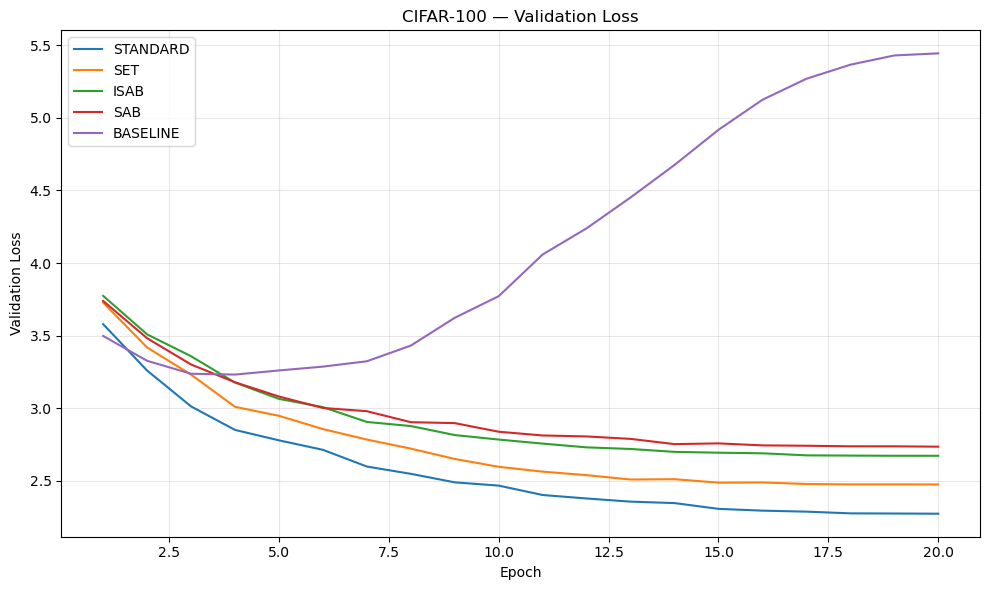

In [3]:

import pandas as pd
import matplotlib.pyplot as plt

models = ["standard", "set", "isab", "sab", "baseline"]

plt.figure(figsize=(10, 6))

for model in models:
    df = pd.read_csv(f"results/cifar_{model}_fraction_100_history.csv")
    plt.plot(df["epoch"], df["val_loss"], label=model.upper())

plt.xlabel("Epoch")
plt.ylabel("Validation Loss")
plt.title("CIFAR-100 — Validation Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig("results/cifar_validation_loss.png", dpi=300)
plt.show()



## Training Loss Comparison

The following graph compares training loss across 20 training epochs for all five models.


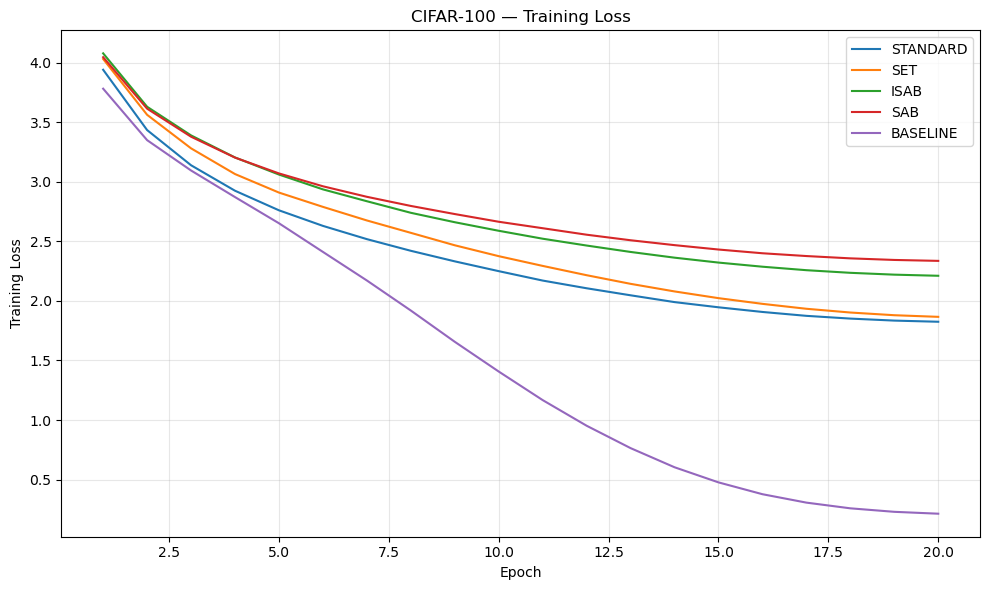

In [4]:

import pandas as pd
import matplotlib.pyplot as plt

models = ["standard", "set", "isab", "sab", "baseline"]

plt.figure(figsize=(10, 6))

for model in models:
    df = pd.read_csv(f"results/cifar_{model}_fraction_100_history.csv")
    plt.plot(df["epoch"], df["train_loss"], label=model.upper())

plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("CIFAR-100 — Training Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig("results/cifar_training_loss.png", dpi=300)
plt.show()



## Test Accuracy Comparison

The following graph compares the final test accuracy of all five models on CIFAR-100.


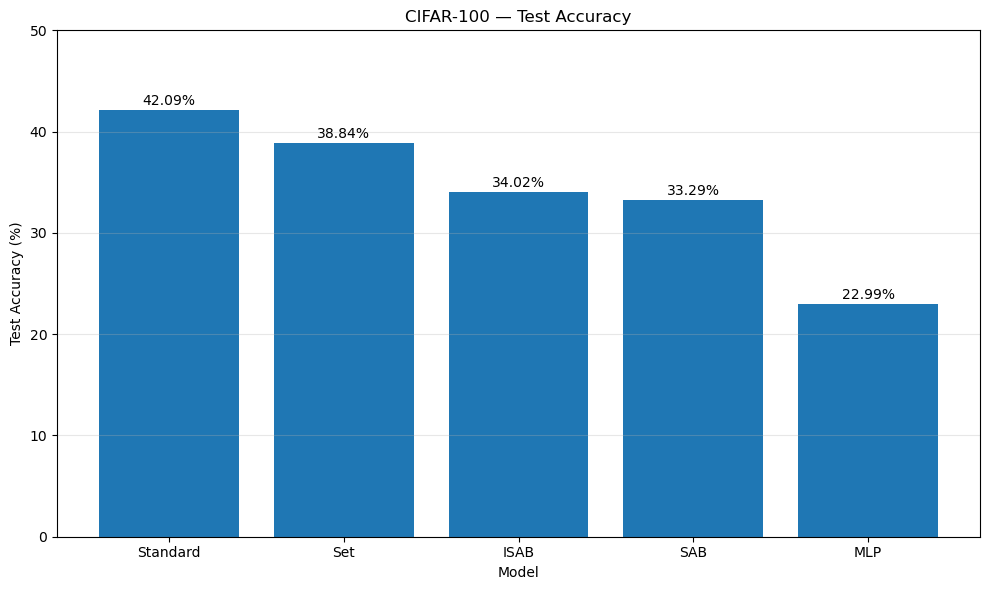

In [5]:

import matplotlib.pyplot as plt

models = ["Standard", "Set", "ISAB", "SAB", "MLP"]
accuracies = [42.09, 38.84, 34.02, 33.29, 22.99]

plt.figure(figsize=(10, 6))

bars = plt.bar(models, accuracies)

for bar, accuracy in zip(bars, accuracies):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.5,
        f"{accuracy:.2f}%",
        ha="center"
    )

plt.xlabel("Model")
plt.ylabel("Test Accuracy (%)")
plt.title("CIFAR-100 — Test Accuracy")
plt.ylim(0, 50)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig("results/cifar_test_accuracy.png", dpi=300)
plt.show()
